## ДЗ 4: детекция объектов

In [ ]:
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5", "torchvision": "torchvision>=0.20",
            "numpy": "numpy", "PIL": "Pillow", "matplotlib": "matplotlib",
            "torchmetrics": "torchmetrics>=1.6,<2", "pycocotools": "pycocotools>=2.0.8,<3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import json
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
    fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, nms, FrozenBatchNorm2d
from torchmetrics.detection import MeanAveragePrecision


import csv
import shutil
import hashlib
from zipfile import ZipFile
from IPython.display import display, Markdown

SEED = 42
BATCH_SIZE = 2
EPOCHS = 30  # для каждой из двух моделей
LR_MILESTONES = [15, 25]
LEARNING_RATE = 0.005
MIN_SIZE = 512
SHOW_SCORE = 0.5  # порог только для картинок; при подсчёте mAP его не применяем
COLAB_WORK = Path("/content/drive/MyDrive/Colab Notebooks/DL/hw4")
WORK = COLAB_WORK if COLAB_WORK.exists() else Path.cwd()  # если не мой коллаб, тогда текущая директория

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
torch.hub.set_dir(str(WORK / "weights"))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Для полного опыта на 30 эпох рекомендуем включить GPU.")


PyTorch: 2.14.1+cu130 | устройство: cuda
GPU: Tesla T4


## 1. Сначала посмотрим на объекты и рамки

Используем предложенный датасет из архива. Он содержит изображения RGB размером 512*512. В отличие от обучающего ноутбука, координаты рамок уже приведены в JSON.

In [4]:
DATA = WORK / "voc_heads_detection_v1"  # распакованная папка с датасетом должна лежать рядом с этим ноутбуком

def load_annotations(split):
    with open(DATA / "annotations" / f"{split}.json", encoding="utf-8") as f:
        coco = json.load(f)

    # получаем названия классов из json
    categories = {item["id"]: item["name"] for item in coco["categories"]}
    records = {}
    id_to_name = {}

    # добавляем изображения
    for item in coco["images"]:
        name = Path(item["file_name"]).stem
        records[name] = {
            "path": DATA / item["file_name"],
            "boxes": [],
            "labels": []}
        id_to_name[item["id"]] = name

    # добавляем рамки
    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        name = id_to_name[ann["image_id"]]
        records[name]["boxes"].append([x, y, x + w, y + h])
        records[name]["labels"].append(ann["category_id"])

    return records, categories


train_records, train_categories = load_annotations("train")
val_records, val_categories = load_annotations("val")

assert train_categories == val_categories

CLASS_NAMES = {0: "background", **train_categories}
NUM_CLASSES = len(CLASS_NAMES)
records = {**train_records, **val_records}
train_names = sorted(train_records)
val_names = sorted(val_records)

# загружаем тестовую выборку
with open(WORK / "sample_submission.csv", encoding="utf-8", newline="") as f:  # sample_submission.csv должен лежать рядом с этим ноутбуком
    test_names = [row["id"] for row in csv.DictReader(f)]

# сопоставляем ID с файлами изображений
test_image_paths = {path.stem: path for path in (DATA / "images" / "test").glob("*.jpg")}

assert len(test_names) == 210 and set(test_names) == set(test_image_paths)

test_records = {
    name: {
        "path": test_image_paths[name],
        "boxes": [],
        "labels": []
    }
    for name in test_names
}

print(f"train: {len(train_names)}, validation: {len(val_names)}, test: {len(test_names)}")

train: 1050, validation: 158, test: 210


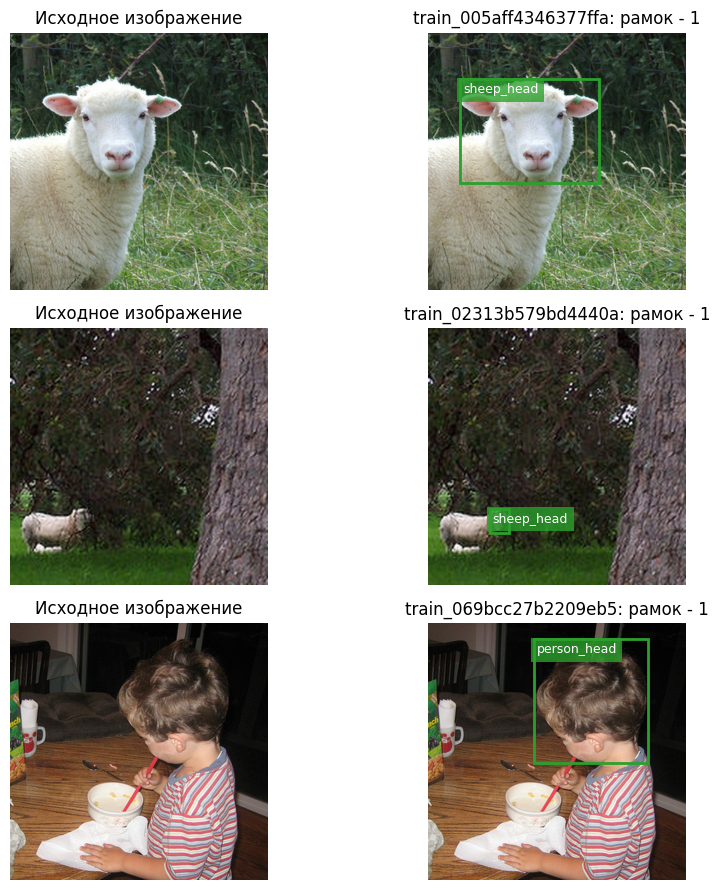

In [5]:
def read_example(name):
    record = records[name]
    with Image.open(record["path"]) as source:
        image = source.convert("RGB")
    target = {"boxes": torch.tensor(record["boxes"], dtype=torch.float32).reshape(-1, 4),
              "labels": torch.tensor(record["labels"], dtype=torch.int64)}
    return image, target

def draw_boxes(ax, boxes, scores=None, color="tab:green", labels=None):
    for i, (x1, y1, x2, y2) in enumerate(torch.as_tensor(boxes).cpu().tolist()):
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2))
        description = ""
        if labels is not None:
            description = CLASS_NAMES[int(labels[i])]
        if scores is not None:
            description += f" {float(scores[i]):.2f}"
        if description:
            # Разносим подписи по высоте, чтобы соседние рамки читались.
            ax.annotate(description.strip(), (x1, y1), xytext=(2, -3 - 12 * (i % 3)),
                        textcoords="offset points", va="top", color="white", fontsize=9,
                        bbox=dict(facecolor=color, alpha=0.8, edgecolor="none"))

fig, axes = plt.subplots(3, 2, figsize=(10, 9))
for row, name in zip(axes, [train_names[i] for i in [0, 10, 30]]):
    image, target = read_example(name)
    row[0].imshow(image)
    row[1].imshow(image); draw_boxes(row[1], target["boxes"], labels=target["labels"])
    for ax, title in zip(row, ["Исходное изображение", f"{name}: рамок - {len(target['boxes'])}"]):
        ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
from collections import Counter

train_counts = Counter(label for record in train_records.values() for label in record["labels"])
val_counts = Counter(label for record in val_records.values() for label in record["labels"])
for class_id in range(1, NUM_CLASSES):
    print(f"{CLASS_NAMES[class_id]:12s} train={train_counts[class_id]:3d} val={val_counts[class_id]:3d}")


person_head  train=284 val= 35
bird_head    train=130 val= 19
cat_head     train=135 val= 20
dog_head     train=137 val= 20
horse_head   train=145 val= 20
sheep_head   train=165 val= 23
cow_head     train=150 val= 22


## 2. Изображения и рамки в батче

У одного фото две рамки, у другого пять. Поэтому таргет (разметка для обучения) хранит **список объектов**,
а не маску фиксированного размера. Для каждого объекта нужны координаты и класс.

Рамка задаётся краями `(xmin, ymin, xmax, ymax)` в пикселях исходного изображения.
Например, `[10, 20, 50, 80]` - прямоугольник шириной 40 и высотой 60.

Батч состоит из **списка изображений и списка словарей** с `boxes` и `labels`.
`collate_fn` собирает эти списки в батч, сохраняя разное число объектов и размеры фото.
RGB переводим в `[0,1]`; изменение размера и нормализацию выполнит сам детектор.

При обучении добавляем случайное горизонтальное отражение. Координаты рамок тоже преобразуем.

In [7]:
def image_tensor(image):
    return torch.from_numpy(np.array(image.convert("RGB"))).permute(2, 0, 1).float() / 255

class HeadsDataset(Dataset):
    def __init__(self, names, augment=False):
        self.names = list(names)
        self.augment = augment
    def __len__(self):
        return len(self.names)
    def __getitem__(self, index):
        image, target = read_example(self.names[index])
        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            boxes = target["boxes"].clone()
            boxes[:, [0, 2]] = (image.width - boxes[:, [2, 0]])
            target["boxes"] = boxes
        return image_tensor(image), target

def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

train_dataset = HeadsDataset(train_names, augment=True)
val_loader = DataLoader(HeadsDataset(val_names, augment=False), batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=0)
images, targets = collate_fn([train_dataset[0], train_dataset[10]])
for image, target in zip(images, targets):
    print("RGB:", tuple(image.shape), "| boxes:", tuple(target["boxes"].shape),
          "| labels:", target["labels"].tolist())


RGB: (3, 512, 512) | boxes: (1, 4) | labels: [6]
RGB: (3, 512, 512) | boxes: (1, 4) | labels: [6]


### Частая ошибка resize: изображение и рамки в разных масштабах

Если преобразовать только размер изображения, координаты рамок останутся в старом масштабе: они съедут, хотя код продолжит работать.
Ниже намеренно испортим пример, а справа исправим его.

При resize координаты x умножаем на `new_width / old_width`,
координаты y - на `new_height / old_height`. В нашем `Dataset` внешнего resize нет:
детектор сам согласует изменение фото и рамок.


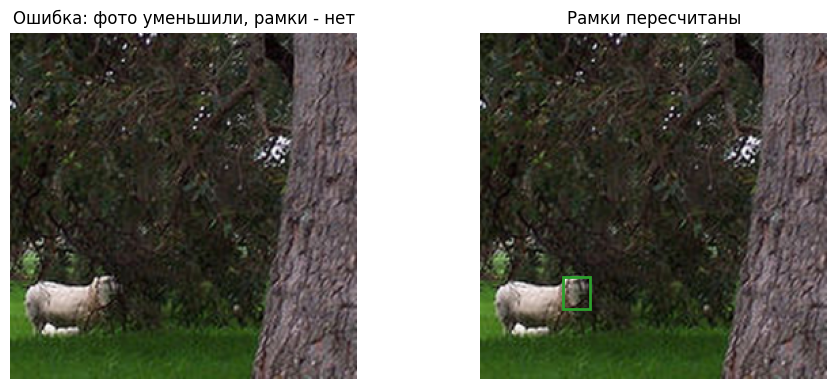

In [8]:
image, target = read_example(train_names[10])
small = image.resize((image.width // 2, image.height // 2))
scale = torch.tensor([small.width / image.width, small.height / image.height] * 2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, boxes, title in zip(axes, [target["boxes"], target["boxes"] * scale],
                           ["Ошибка: фото уменьшили, рамки - нет", "Рамки пересчитаны"]):
    ax.imshow(small); draw_boxes(ax, boxes)
    ax.set(xlim=(0, small.width), ylim=(small.height, 0), title=title); ax.axis("off")
plt.tight_layout(); plt.show()


## 3. От R-CNN к Faster R-CNN

Как найти объекты, если их положение заранее неизвестно? Сначала можно предложить
области-кандидаты, а затем проверить каждую: есть ли там объект, какой это класс
и куда точнее поставить рамку? На этой идее построено семейство **R-CNN (Region-based Convolutional Neural Network)**.
На схеме проследите, где вычисляются признаки и откуда приходят области-кандидаты.


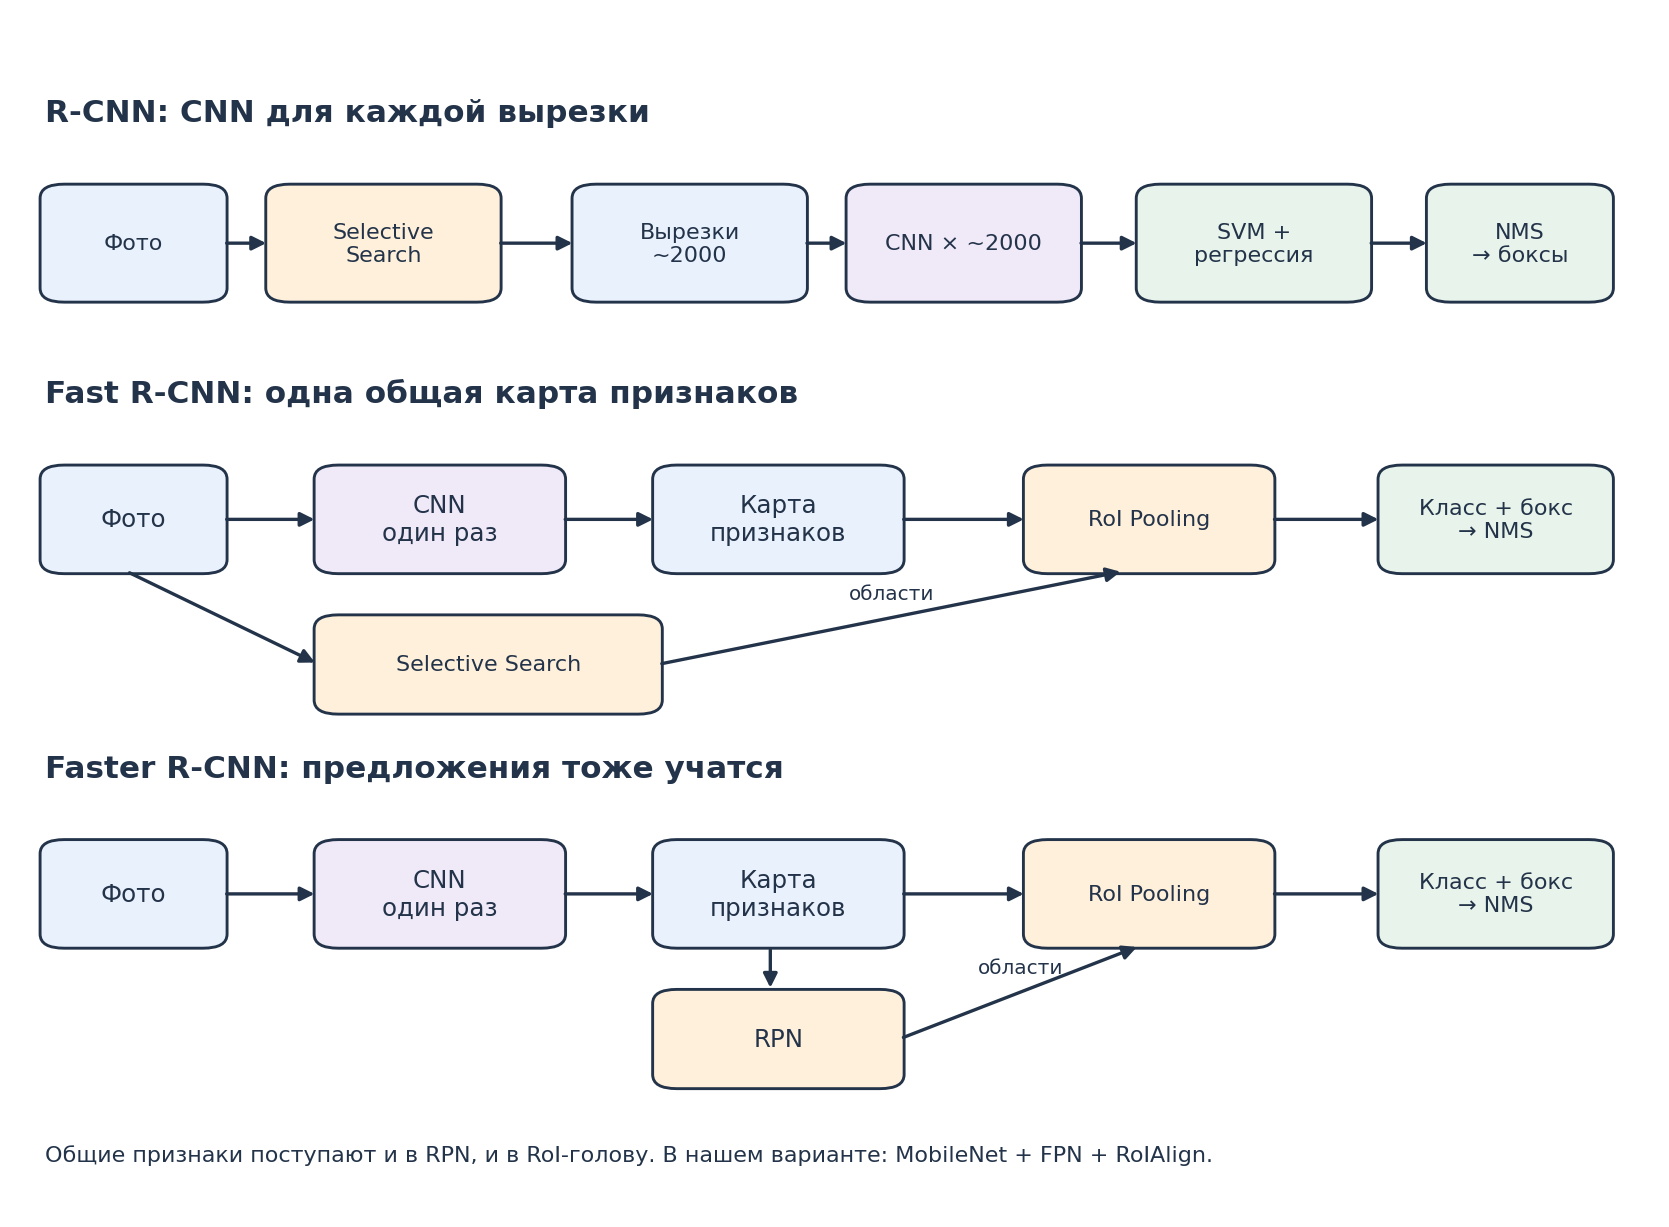


**R-CNN (2014): проверяем каждую область отдельно.** Selective Search предлагает
около 2000 областей по структуре изображения. Каждую область приводят к нужному
размеру и пропускают через CNN, чтобы получить вектор признаков. SVM определяет класс, регрессор поправляет рамку.
Области часто перекрываются, поэтому CNN много раз вычисляет признаки для одних
и тех же пикселей, а это в свою очередь замедляет работу модели. Кроме того, один объект может получить
несколько рамок. Убирать такие дубли будем с помощью **NMS (подавления немаксимумов)** -
разберём его чуть ниже.

**Fast R-CNN (2015): а если посчитать признаки один раз?** CNN обрабатывает всё фото и получается карта признаков.
Для каждой области интереса - **RoI (region of interest)** - операция
**RoI Pooling** извлекает из общей карты признаки фиксированного размера.
Голова (выходные слои сети) предсказывает класс и поправки рамки. Повторных проходов CNN больше нет, но Selective Search остался отдельным алгоритмом и все еще занимает много времени.

**Faster R-CNN (2015): научим сеть предлагать области.** Маленькая сеть **RPN (Region Proposal Network)** работает
на той же карте признаков и заменяет Selective Search. Для каждой опорной рамки она решает две задачи:
**бинарную классификацию** (соответствует ли рамка объекту или фону)
и **регрессию** (как изменить координаты рамки, чтобы точнее выделить объект).

В каждой точке карты признаков заранее разместим несколько прямоугольников разных
размеров и пропорций. Это **опорные рамки (anchors)**. Для каждой из них RPN решает,
соответствует ли она объекту или фону, и предсказывает поправки к координатам.
Так из заранее заданных рамок получаются кандидаты на реальные объекты.
Вероятность класса «объект» также называют **objectness**.
Регрессор выдаёт четыре поправки: сдвиг центра и изменение ширины/высоты. Скорректированные
рамки после отбора становятся **предложенными областями (proposals)**
для следующей головы.

Затем голова детектора уточняет области и конкретные классы объектов. Признаки изображения
общие, а поиск кандидатов и их уточнение образуют всего два этапа. Именно эту модель мы с вами рассмотрим в этом уроке.

В нашем варианте **бэкбон (backbone)** - сеть для извлечения признаков - это MobileNetV3. Она легкая и её можно запускать на слабых устройствах.
**FPN (Feature Pyramid Network)** объединяет карты признаков разных масштабов.
В нашем детекторе признаки RoI извлекает **RoIAlign**: как и RoI Pooling,
она получает признаки фиксированного размера, но без грубого округления координат.
Применение сети к новому изображению дальше будем называть **инференсом (inference)**.

Оригинальные статьи: [R-CNN](https://arxiv.org/abs/1311.2524),
[Fast R-CNN](https://arxiv.org/abs/1504.08083), [Faster R-CNN](https://arxiv.org/abs/1506.01497).


### Инициализация: случайные веса и предобучение

Можно начать обучение с готовых весов модели, которая уже научилась находить объекты на COCO.

Будем дообучать две модели и смотреть, какая из них лучше детектирует объекты.

| | MobileNetV3 Large 320 FPN | ResNet50 FPN v2 |
|---|---|---|
| Начальные веса | Перенос весов детектора COCO | Перенос весов детектора COCO |
| Выход для нашей задачи | Такая же новая голова: фон + 7 классов | Такая же новая голова: фон + 7 классов |
| Что обучаем | Все слои | Все слои |

Для эксперимента используем две модели семейства Faster R-CNN.

**Faster R-CNN MobileNetV3 Large 320 FPN** - лёгкая сеть, использованная в обучающем ноутбуке.

**Faster R-CNN ResNet50 FPN v2** - более крупная модель с другим backbone, проверим ее как альтернативу.

In [9]:
# веса скачаны с контеста
# файлы должны лежать рядом с этим ноутбуком

cache_dir = Path(torch.hub.get_dir()) / "checkpoints"
cache_dir.mkdir(parents=True, exist_ok=True)

for filename in ["fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth","fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth"]:
    weights_file = WORK / filename
    shutil.copy2(weights_file, cache_dir / filename)

In [10]:
MODEL_CONFIG = dict(min_size=MIN_SIZE, max_size=640, box_score_thresh=0.001,
                    box_nms_thresh=0.5, box_detections_per_img=100,
                    rpn_score_thresh=0.0, rpn_pre_nms_top_n_test=150,
                    rpn_post_nms_top_n_test=150)

def make_model(pretrained=False, config=None, architecture="mobilenet"):
    if architecture == "mobilenet":
        constructor = fasterrcnn_mobilenet_v3_large_320_fpn
        weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1 if pretrained else None
    else:
        constructor = fasterrcnn_resnet50_fpn_v2
        weights = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1 if pretrained else None
    model = constructor(
        weights=weights, weights_backbone=None,
        **(MODEL_CONFIG if config is None else config))
    # Одинаковая обучаемая нормализация; при COCO сохраняем её исходное состояние.
    for name, layer in list(model.backbone.named_modules()):
        if isinstance(layer, FrozenBatchNorm2d):
            norm = nn.BatchNorm2d(layer.weight.numel(), eps=layer.eps)
            norm.load_state_dict({key: getattr(layer, key) for key in
                                  ["weight", "bias", "running_mean", "running_var"]}, strict=False)
            parent, child = name.rsplit(".", 1)
            setattr(model.backbone.get_submodule(parent), child, norm)
    features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(features, num_classes=NUM_CLASSES)
    for parameter in model.parameters():
        parameter.requires_grad = True
    return model

## 6. Обучаем обе модели

Теперь нужно научить сеть давать правильные классы и координаты. Что считать
обучающим примером: опорную рамку, предложенную область или итоговую рамку после NMS?
В Faster R-CNN есть два этапа, и для каждого мы готовим свои примеры.

### Положительные и отрицательные примеры

При обучении каждому кандидату назначаем метку. **Положительный пример**
соответствует конкретному объекту GT: сеть должна определить его класс и уточнить
координаты рамки. Для **отрицательного примера** правильный класс - «фон»;
координаты для него не обучаем.

Для RPN классов всего два: «объект» и «фон». RoI-голова уже различает
конкретные классы объектов.

Это метки для обучения, а не знак score и не «хорошее / плохое» предсказание.
Отрицательная область может задевать человека: важно, достаточно ли совпадение с GT.

В нашем torchvision-варианте правила такие:

| Кандидат | Положительный | Отрицательный | Не участвует в лоссе |
|---|---|---|---|
| Опорная рамка для RPN | Лучший IoU с GT ≥ 0.7; также действует правило лучшего совпадения с GT | IoU < 0.3, если не выбрана правилом лучшего совпадения | Остальные опорные рамки с 0.3 ≤ IoU < 0.7 |
| Предложенная область для RoI-головы | Лучший IoU с GT ≥ 0.5 | IoU < 0.5 | Промежутка между порогами здесь нет |

Правило лучшего совпадения дополнительно помечает лучшие опорные рамки для каждого GT
как положительные, даже если IoU ниже 0.7. Так объект с неудобной геометрией
тоже может дать положительные примеры. Из кандидатов затем берут подвыборку
положительных и отрицательных, чтобы многочисленный фон не определял весь лосс.

Например, при IoU 0.8 и опорная рамка, и предложенная область положительны;
при 0.1 обычно отрицательны. При 0.6 опорная рамка обычно игнорируется,
а предложенная область уже положительна.
Пороги относятся к **обучению**, а не к NMS и не к зачёту TP в метрике.

### От опорных рамок к лоссам двух голов

**Логиты** - выходные числа до sigmoid/softmax. Классификационные функции потерь
получают именно логиты: нужное преобразование уже находится внутри лосса.

1. **RPN** предсказывает вероятность класса «объект» и смещения для опорных рамок.
   Метки 1/0 и целевые смещения получаем из GT. Оба лосса RPN считаем
   по исходным предсказаниям **до NMS RPN**.
2. Для следующей головы смещения превращаются в координаты предложенных областей,
   кандидаты фильтруются и проходят **NMS RPN - при обучении и при инференсе**.
3. Во время обучения к предложенным областям добавляют GT-рамки, сопоставляют области с GT
   и выбирают положительные/отрицательные RoI. Положительной RoI назначают
   класс головы, отрицательной - класс «фон».
4. RoI-голова предсказывает классы и смещения. Её два лосса считаются
   **до финальной NMS**. При `train()` финальная NMS вообще не вызывается.

Несколько положительных опорных рамок или RoI могут относиться к одному GT - это
нормальные обучающие примеры. В отличие от AP, здесь не надо объявлять второй
такой пример дублем и превращать его в отрицательный.

На схеме каждый лосс подписан у того выхода, который он обучает.


### Что штрафует каждый лосс

1. **`loss_objectness` - есть ли в опорной рамке объект?** Бинарная кросс-энтропия сравнивает
   оценку RPN с меткой 1 у положительной опорной рамки и 0 у отрицательной.
   Для одного положительного примера вероятность 0.1 даёт штраф −log(0.1) ≈ 2.30,
   а 0.9 - всего 0.105. Неверная уверенность стоит дороже.
2. **`loss_rpn_box_reg` - как сдвинуть опорную рамку к GT?** По GT вычисляем,
   насколько нужно сдвинуть центр рамки и изменить её ширину и высоту.
   Лосс сравнивает эти четыре поправки с предсказанными.
   Здесь участвуют **только положительные опорные рамки**. Для фона нет рамки-цели.
3. **`loss_classifier` - какой класс у RoI?** Кросс-энтропия штрафует неверный класс
   выбранной области. У положительной RoI это класс GT, у отрицательной - фон.
   RPN решала бинарную классификацию без различения типов объектов;
   эта голова определяет конкретный класс объекта.
4. **`loss_box_reg` - как уточнить предложенную область?** Снова сравниваем
   предсказанные и целевые поправки, но теперь относительно RoI. Для каждой
   **положительной RoI** берём поправки, предсказанные для её правильного класса,
   и сравниваем с целевыми. Отрицательные RoI в этот лосс не входят: для фона
   нет правильной рамки.

Оба координатных лосса используют **Smooth L1**. При маленькой ошибке этот лосс
похож на квадрат ошибки, а при большой растёт линейно. Поэтому отдельные крупные
ошибки меньше влияют на лосс, чем при MSE. Сравниваются
**смещения относительно опорной рамки или предложенной области**, а не сырые координаты в пикселях
и не IoU готовых рамок. Нулевые смещения оставили бы исходную рамку на месте.

В `train_epoch` складываем четыре лосса и вызываем `backward()`. Каждый лосс
обучает свою голову, а общий бэкбон получает градиенты от обеих голов.

При этом лоссы RoI-головы не обучают RPN через координаты предложенных областей:
перед отбором областей предсказания RPN отсоединяются от графа с помощью `detach`.
Сама RPN обучается по двум собственным лоссам, рассчитанным до её NMS.

При `eval()` получаем уже готовые рамки, оценки уверенности и классы
после постобработки, в координатах исходной фотографии.

Реализация: [RPN](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/rpn.py),
[RoIHeads / fastrcnn_loss](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/roi_heads.py)
и [пороги сопоставления Faster R-CNN](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/faster_rcnn.py).


In [11]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, count = 0.0, 0
    for images, targets in loader:
        images = [image.to(DEVICE) for image in images]
        targets = [{key: value.to(DEVICE) for key, value in t.items()} for t in targets]
        optimizer.zero_grad()
        loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise ValueError("Loss стал NaN/Inf: проверьте рамки и learning rate")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)
        count += len(images)
    return total_loss / count

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", backend="pycocotools",
                                  max_detection_thresholds=[1, 10, 100])
    for images, targets in loader:
        predictions = model([image.to(DEVICE) for image in images])
        predictions = [{key: value.cpu() for key, value in p.items()} for p in predictions]
        metric.update(predictions, targets)
    result = metric.compute()
    return float(result["map"]), float(result["map_50"])


Сохраняем лучшую эпоху каждой модели по mAP на валидации. Затем по той же метрике выбираем одну из двух моделей для дальнейшего получения предсказаний.

In [12]:
results = []
for tag, title in [("mobilenet", "Faster R-CNN MobileNetV3"), ("resnet50", "Faster R-CNN ResNet50 FPN v2")]:
    set_seed(SEED)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn,
                              num_workers=0, generator=torch.Generator().manual_seed(SEED))
    model = make_model(pretrained=True, architecture=tag).to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=LR_MILESTONES, gamma=0.1)
    history = []
    best_map, best_ap50, best_epoch = -1., 0., 0
    path = WORK / f"{tag}.pt"
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        epoch_lr = optimizer.param_groups[0]["lr"]
        train_loss = train_epoch(model, train_loader, optimizer)
        val_map, val_ap50 = evaluate(model, val_loader)
        history.append(dict(epoch=epoch, loss=train_loss, map=val_map, ap50=val_ap50, lr=epoch_lr))
        if val_map > best_map:
            best_map, best_ap50, best_epoch = val_map, val_ap50, epoch
            torch.save({"model": model.state_dict(), "architecture": tag,
                        "config": MODEL_CONFIG, "class_names": CLASS_NAMES,
                        "initial_weights": "COCO_V1", "label": title,
                        "normalization": "BatchNorm2d", "seed": SEED, "epoch": epoch, "val_map": val_map,
                        "training": {"epochs": EPOCHS, "lr": LEARNING_RATE, "milestones": LR_MILESTONES},
                        "preprocessing": {"image_mean": model.transform.image_mean, "image_std": model.transform.image_std},
                        "splits": {"train": train_names, "val": val_names, "test": test_names}}, path)
        print(f"{title}, {epoch}/{EPOCHS}: loss={train_loss:.3f}, val mAP={val_map:.3f}, AP50={val_ap50:.3f}, lr={epoch_lr:g}")
        scheduler.step()
    results.append(dict(tag=tag, title=title, label=title, map=best_map, ap50=best_ap50, epoch=best_epoch,
                        seconds=time.perf_counter()-started, path=str(path), history=history))
    del model, optimizer
winner = max(results, key=lambda row: row["map"])
checkpoint_path = WORK / "heads_best_val.pt"
shutil.copy2(winner["path"], checkpoint_path)
print("Выбрана модель:", winner["label"], "| лучшая эпоха:", winner["epoch"], "| val mAP:", winner["map"])

(WORK / "training_comparison.json").write_text(json.dumps(
    {"seed": SEED, "epochs": EPOCHS, "device": str(DEVICE), "results": results},
    ensure_ascii=False, indent=2), encoding="utf-8")


Faster R-CNN MobileNetV3, 1/30: loss=0.362, val mAP=0.235, AP50=0.502, lr=0.005
Faster R-CNN MobileNetV3, 2/30: loss=0.235, val mAP=0.326, AP50=0.640, lr=0.005
Faster R-CNN MobileNetV3, 3/30: loss=0.191, val mAP=0.374, AP50=0.685, lr=0.005
Faster R-CNN MobileNetV3, 4/30: loss=0.161, val mAP=0.339, AP50=0.638, lr=0.005
Faster R-CNN MobileNetV3, 5/30: loss=0.139, val mAP=0.377, AP50=0.726, lr=0.005
Faster R-CNN MobileNetV3, 6/30: loss=0.130, val mAP=0.377, AP50=0.715, lr=0.005
Faster R-CNN MobileNetV3, 7/30: loss=0.113, val mAP=0.347, AP50=0.707, lr=0.005
Faster R-CNN MobileNetV3, 8/30: loss=0.104, val mAP=0.372, AP50=0.711, lr=0.005
Faster R-CNN MobileNetV3, 9/30: loss=0.095, val mAP=0.417, AP50=0.740, lr=0.005
Faster R-CNN MobileNetV3, 10/30: loss=0.090, val mAP=0.404, AP50=0.733, lr=0.005
Faster R-CNN MobileNetV3, 11/30: loss=0.085, val mAP=0.404, AP50=0.700, lr=0.005
Faster R-CNN MobileNetV3, 12/30: loss=0.078, val mAP=0.410, AP50=0.723, lr=0.005
Faster R-CNN MobileNetV3, 13/30: loss

11574

_Google Collab почему-то задваивает вывод ячеек..._

| Модель | Лучшая эпоха | Val mAP | AP50 той же эпохи | Время, мин |
|---|---:|---:|---:|---:|
| Faster R-CNN MobileNetV3 | 22 | 0.454 | 0.746 | 42.8 |
| Faster R-CNN ResNet50 FPN v2 | 25 | 0.601 | 0.848 | 149.0 |

| Модель | Лучшая эпоха | Val mAP | AP50 той же эпохи | Время, мин |
|---|---:|---:|---:|---:|
| Faster R-CNN MobileNetV3 | 22 | 0.454 | 0.746 | 42.8 |
| Faster R-CNN ResNet50 FPN v2 | 25 | 0.601 | 0.848 | 149.0 |

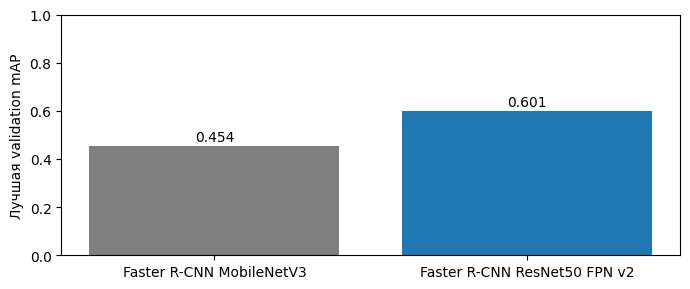

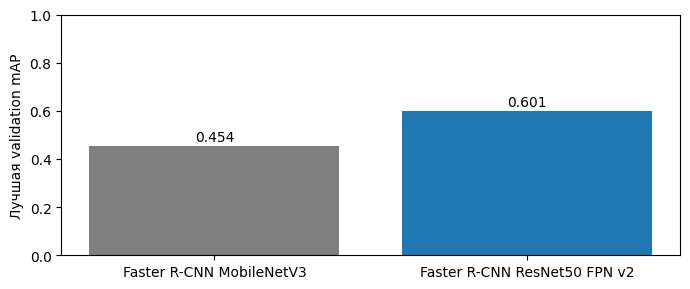

In [13]:
header = "| Модель | Лучшая эпоха | Val mAP | AP50 той же эпохи | Время, мин |\n|---|---:|---:|---:|---:|\n"
rows = [f"| {r['title']} | {r['epoch']} | {r['map']:.3f} | {r['ap50']:.3f} | {r['seconds']/60:.1f} |" for r in results]
display(Markdown(header + "\n".join(rows)))
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([r["label"] for r in results], [r["map"] for r in results], color=["tab:gray", "tab:blue"])
ax.set(ylabel="Лучшая validation mAP", ylim=(0, 1))
for i, row in enumerate(results):
    ax.text(i, row["map"] + 0.02, f"{row['map']:.3f}", ha="center")
plt.tight_layout(); plt.show()


ResNet показала себя лучше, поэтому для дальнейших экспериментов
будем использовать её.

## 7. Разбираем ошибки выбранной модели

Загрузим выбранные веса в новую модель. Слева - зелёная разметка,
справа - оранжевые ответы при `SHOW_SCORE`. Начнём с трёх фиксированных
фотографий валидационной выборки: они помогут сравнить изменения модели в будущих опытах.


In [14]:
@torch.inference_mode()
def predict(model, image):
    model.eval()
    answer = model([image_tensor(image).to(DEVICE)])[0]
    return {key: value.cpu() for key, value in answer.items()}

def show_predictions(model, names, threshold=0.5):
    fig, axes = plt.subplots(len(names), 2, figsize=(10, 3.5 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, target = read_example(name)
        answer = predict(model, image)
        shown = answer["scores"] >= threshold
        for ax in row:
            ax.imshow(image); ax.axis("off")
        draw_boxes(row[0], target["boxes"], labels=target["labels"])
        draw_boxes(row[1], answer["boxes"][shown], answer["scores"][shown], color="tab:orange", labels=answer["labels"][shown])
        row[0].set_title(f"{name}: разметка")
        row[1].set_title(f"Предсказания, score ≥ {threshold}")
    plt.tight_layout(); plt.show()

checkpoint_path = WORK / "heads_best_val.pt"
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
selected_model = make_model(config=saved["config"], architecture=saved["architecture"]).to(DEVICE)
selected_model.load_state_dict(saved["model"])
selected_model.transform.image_mean = saved["preprocessing"]["image_mean"]
selected_model.transform.image_std = saved["preprocessing"]["image_std"]
selected_model.eval()

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, t

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, t

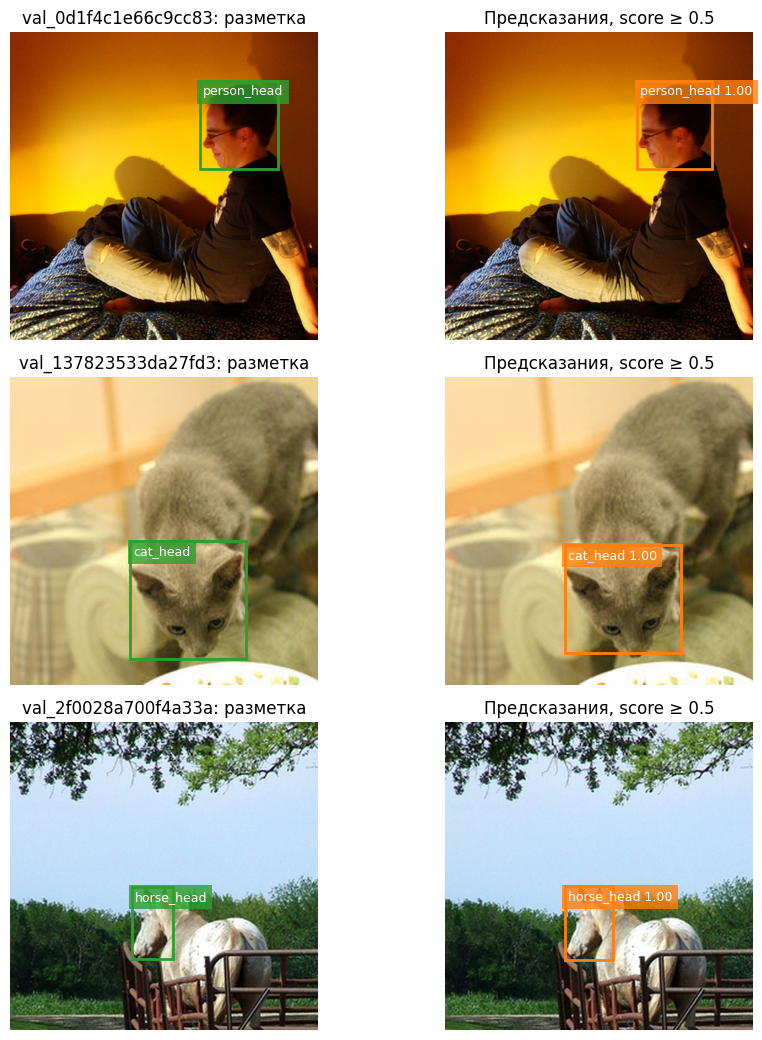

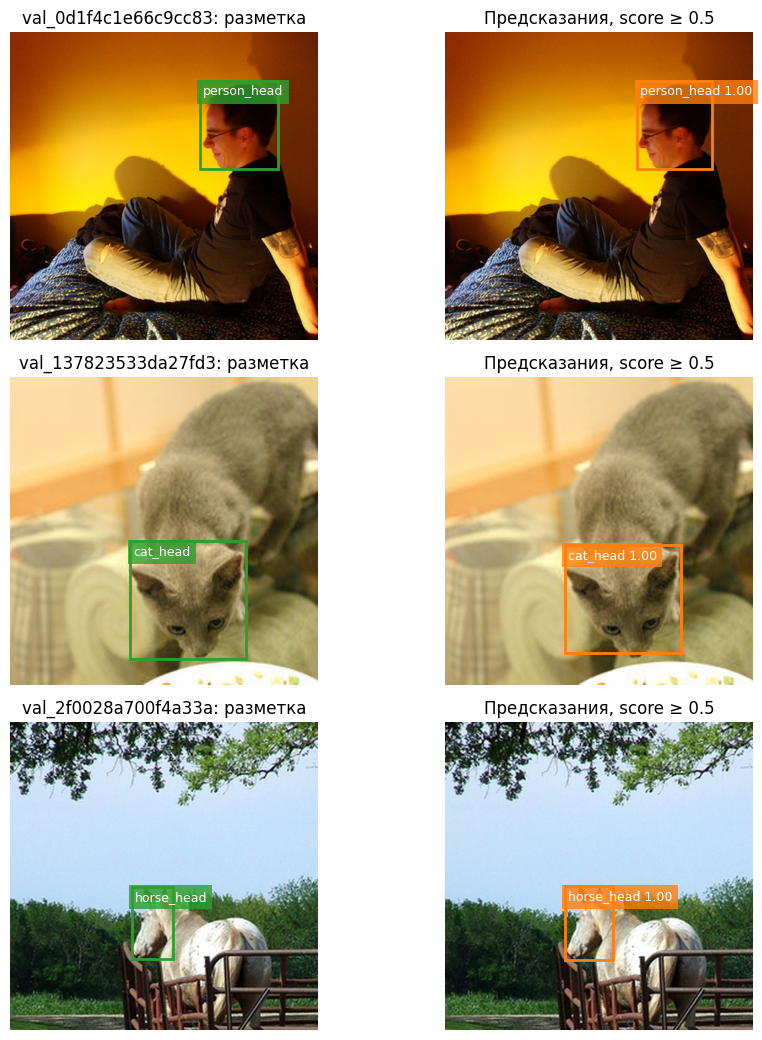

In [15]:
show_predictions(selected_model, [val_names[i] for i in [5, 15, 25]], SHOW_SCORE)

На трёх примерах из валидационной выборки модель правильно определила (с уверенностью 1) классы `person_head`, `cat_head` и `horse_head`.

## 8. Диагностика без нового обучения

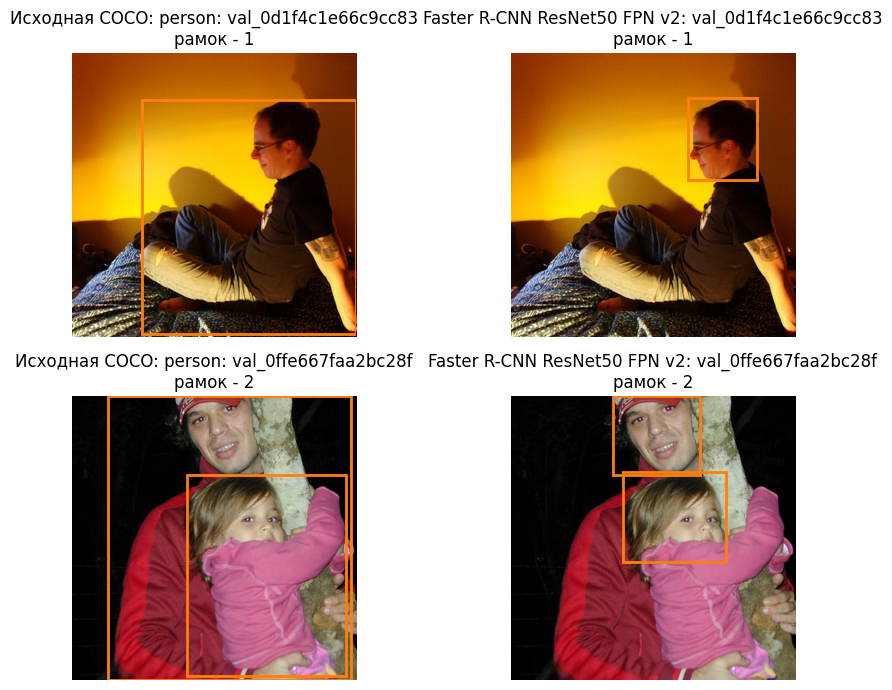

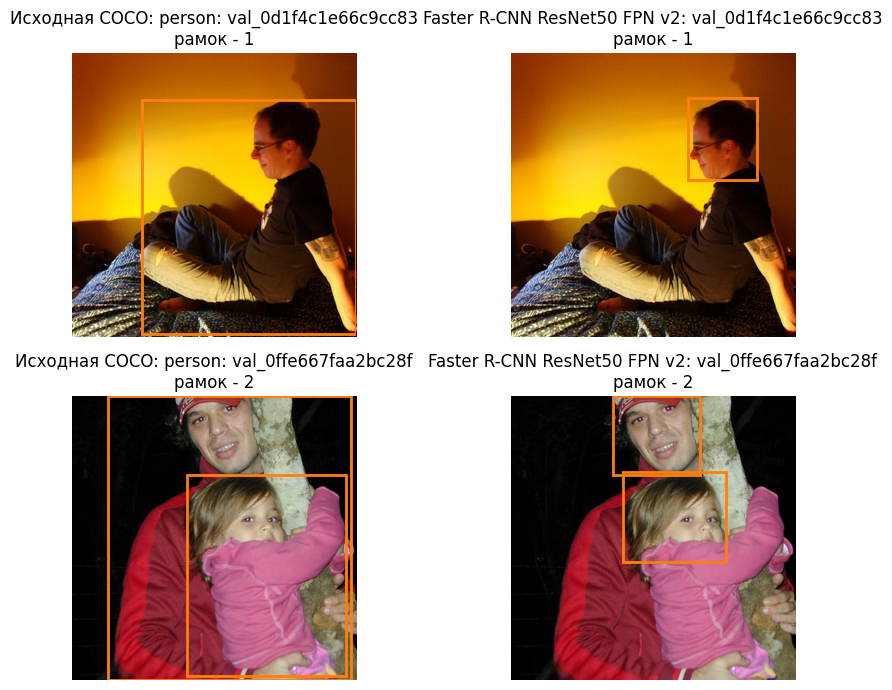

In [16]:
if saved["architecture"] == "mobilenet":
    coco_weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1
    constructor = fasterrcnn_mobilenet_v3_large_320_fpn
else:
    coco_weights = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
    constructor = fasterrcnn_resnet50_fpn_v2
coco_model = constructor(weights=coco_weights, weights_backbone=None, **saved["config"]).to(DEVICE).eval()
person_id = coco_weights.meta["categories"].index("person")

# выбираем два изображения с головами людей
comparison_names = [name for name in val_names if 1 in records[name]["labels"]][:2]
assert len(comparison_names) == 2

comparison_counts = []
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, name in zip(axes, comparison_names):
    image, _ = read_example(name)
    counts = []
    for ax, detector, class_id, title in zip(
            row, [coco_model, selected_model], [person_id, 1], ["Исходная COCO: person", saved["label"]]):
        prediction = predict(detector, image)
        shown = (prediction["labels"] == class_id) & (prediction["scores"] >= SHOW_SCORE)
        counts.append(int(shown.sum()))
        ax.imshow(image); ax.axis("off")
        draw_boxes(ax, prediction["boxes"][shown], color="tab:orange")
        ax.set_title(f"{title}: {name}\nрамок - {counts[-1]}")
    comparison_counts.append(counts)
plt.tight_layout(); plt.show()
del coco_model


Как видно по изображениям, дообучение позволило адаптировать детектор к задаче распознавания голов.

### Порог показа ответов

Один раз запустим детектор на фотографии и покажем результат с тремя порогами:
0.2, 0.5 и 0.8.

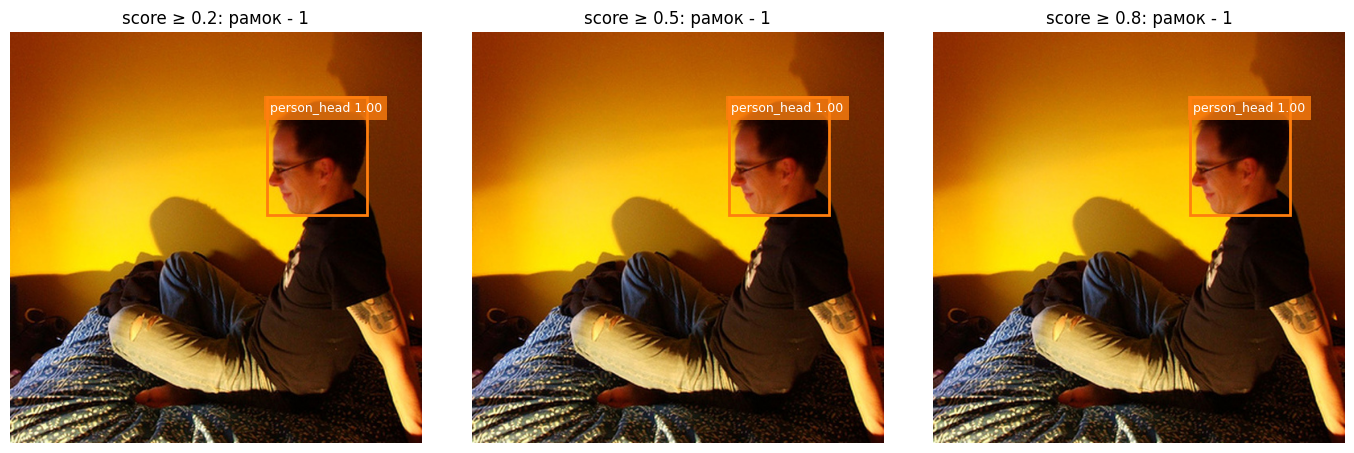

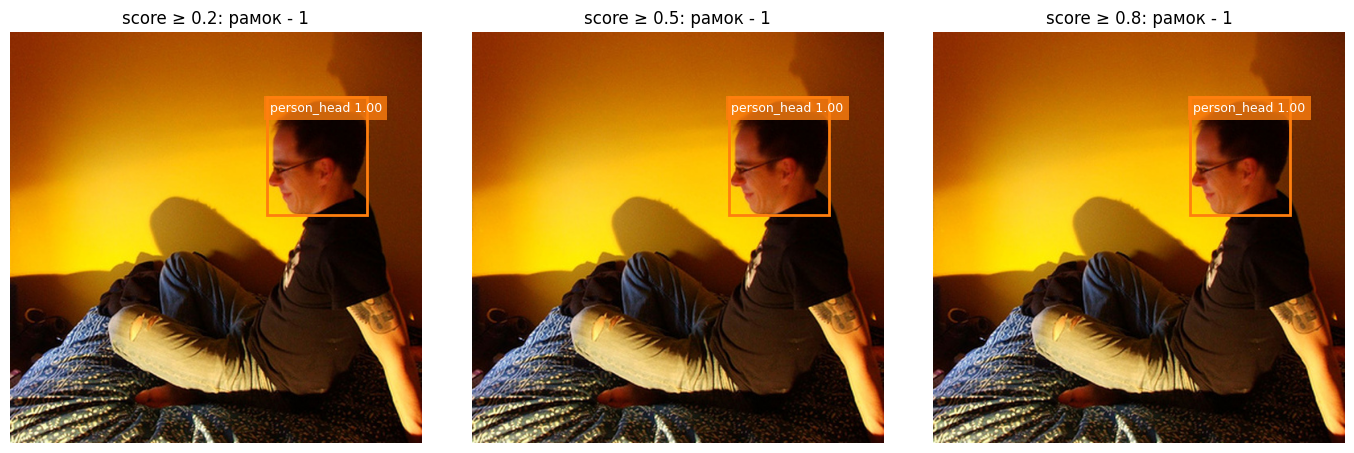

In [17]:
threshold_image, _ = read_example(comparison_names[0])
threshold_answer = predict(selected_model, threshold_image)
threshold_counts = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, threshold in zip(axes, [0.2, 0.5, 0.8]):
    shown = threshold_answer["scores"] >= threshold
    threshold_counts.append(int(shown.sum()))
    ax.imshow(threshold_image); ax.axis("off")
    draw_boxes(ax, threshold_answer["boxes"][shown], threshold_answer["scores"][shown], color="tab:orange", labels=threshold_answer["labels"][shown])
    ax.set_title(f"score ≥ {threshold}: рамок - {threshold_counts[-1]}")
plt.tight_layout(); plt.show()


Для выбранного изображения во всех трёх случаях сохранилась рамка класса $person\_head$ с уверенностью 1.00. Изменение порога не повлияло на результат, что объясняется высокой уверенностью модели в данном предсказании.

### Размер входа: качество и скорость

Увеличим внутренний размер входа с 512 до 640 по короткой стороне,
не меняя веса.

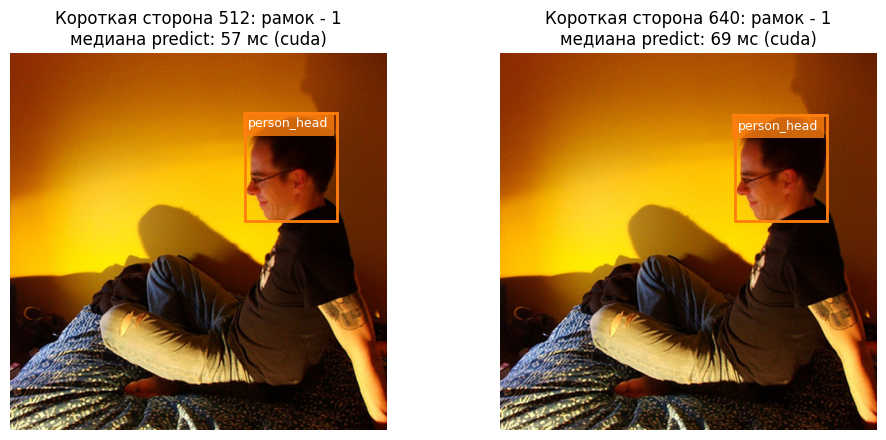

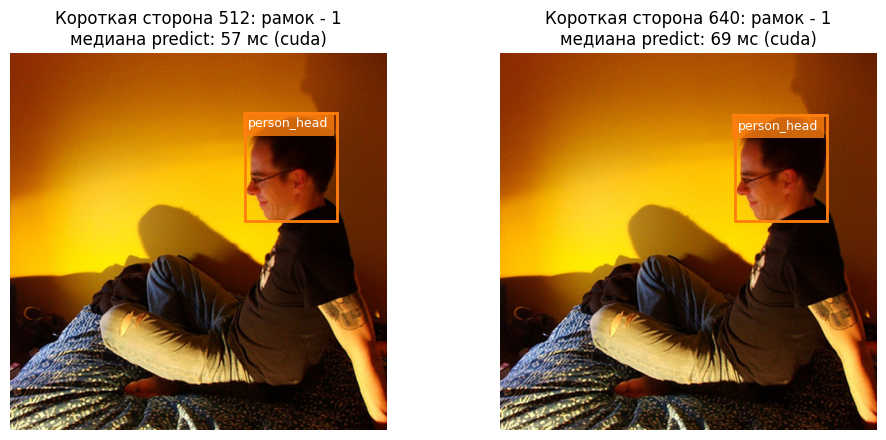

In [18]:
resolution_image, _ = read_example(comparison_names[0])
old_min, old_max = selected_model.transform.min_size, selected_model.transform.max_size
resolution_results = []
try:
    for side in [512, 640]:
        selected_model.transform.min_size = (side,)
        selected_model.transform.max_size = 640
        predict(selected_model, resolution_image)  # прогрев
        durations = []
        for _ in range(3):
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            started = time.perf_counter()
            prediction = predict(selected_model, resolution_image)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            durations.append(time.perf_counter() - started)
        resolution_results.append((side, prediction, float(np.median(durations))))
finally:
    selected_model.transform.min_size, selected_model.transform.max_size = old_min, old_max
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (side, prediction, seconds) in zip(axes, resolution_results):
    shown = prediction["scores"] >= SHOW_SCORE
    ax.imshow(resolution_image); ax.axis("off")
    draw_boxes(ax, prediction["boxes"][shown], color="tab:orange", labels=prediction["labels"][shown])
    ax.set_title(f"Короткая сторона {side}: рамок - {int(shown.sum())}\nмедиана predict: {seconds*1000:.0f} мс ({DEVICE.type})")
plt.tight_layout(); plt.show()


В обоих случаях модель нашла голову человека. Визуально рамки не отличаются. Медианное время предсказания увеличилось с 57 до 69 мс.

Таким образом, увеличение размера входа не дало преимущества на данном изображении, однако потребовало больше времени.

## 9. Итоговое обучение

Продолжаем обучение лучшей модели на объединённых train и val.

Для дообучения используем небольшой learning rate и несколько эпох.

In [19]:
FINAL_EPOCHS = 2
FINAL_LR = 0.00005

set_seed(SEED)
full_dataset = HeadsDataset(train_names + val_names, augment=True)
full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True,
                         collate_fn=collate_fn, num_workers=0,
                         generator=torch.Generator().manual_seed(SEED))

del selected_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

# продолжаем обучение лучшей модели
final_model = make_model(config=saved["config"], architecture=saved["architecture"]).to(DEVICE)
final_model.load_state_dict(saved["model"])
final_model.transform.image_mean = saved["preprocessing"]["image_mean"]
final_model.transform.image_std = saved["preprocessing"]["image_std"]

final_optimizer = torch.optim.SGD(final_model.parameters(), lr=FINAL_LR, momentum=0.9, weight_decay=0.0005)
for epoch in range(1, FINAL_EPOCHS + 1):
    train_loss = train_epoch(final_model, full_loader, final_optimizer)
    print(f"Train + val, {epoch}/{FINAL_EPOCHS}: loss={train_loss:.3f}")

final_checkpoint_path = WORK / "heads_final_train_val.pt"
torch.save({"model": final_model.state_dict(), "architecture": saved["architecture"],
            "config": saved["config"], "class_names": saved["class_names"],
            "label": saved["label"], "preprocessing": saved["preprocessing"],
            "training": {"split": "train+val", "base_epoch": saved["epoch"], "extra_epochs": FINAL_EPOCHS, "lr": FINAL_LR}}, final_checkpoint_path)
print("Финальная модель сохранена:", final_checkpoint_path)

del final_model, final_optimizer
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Train + val, 1/2: loss=0.035
Train + val, 1/2: loss=0.035
Train + val, 2/2: loss=0.031
Train + val, 2/2: loss=0.031
Финальная модель сохранена: /content/drive/MyDrive/Colab Notebooks/DL/hw4/heads_final_train_val.pt
Финальная модель сохранена: /content/drive/MyDrive/Colab Notebooks/DL/hw4/heads_final_train_val.pt


In [28]:
# выбираем модель для предсказаний
PREDICT_CHECKPOINT = WORK / "heads_final_train_val.pt"
loaded = torch.load(PREDICT_CHECKPOINT, map_location="cpu", weights_only=True)
inference_model = make_model(config=loaded["config"], architecture=loaded["architecture"]).to(DEVICE)
inference_model.load_state_dict(loaded["model"])
inference_model.transform.image_mean = loaded["preprocessing"]["image_mean"]
inference_model.transform.image_std = loaded["preprocessing"]["image_std"]
inference_model.eval()

name = test_names[0]
photo_path = test_records[name]["path"]
with Image.open(photo_path) as source:
    photo = source.convert("RGB")
answer = predict(inference_model, photo)

output = {"id": photo_path.stem, "width": photo.width, "height": photo.height,
          "boxes_xyxy": answer["boxes"].tolist(), "labels": answer["labels"].tolist(),
          "scores": answer["scores"].tolist(), "class_names": loaded["class_names"]}
output_path = WORK / f"{photo_path.stem}_detections.json"
output_path.write_text(json.dumps(output, ensure_ascii=False, indent=2), encoding="utf-8")
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(photo); ax.axis("off")
shown = answer["scores"] >= SHOW_SCORE
draw_boxes(ax, answer["boxes"][shown], answer["scores"][shown], color="tab:orange", labels=answer["labels"][shown])
figure_path = WORK / f"{photo_path.stem}_detections.png"
fig.savefig(figure_path, bbox_inches="tight"); plt.close(fig)

print("Модель:", final_checkpoint_path)
print("Ответы:", output_path, "| рисунок:", figure_path)

Модель: /content/drive/MyDrive/Colab Notebooks/DL/hw4/heads_final_train_val.pt
Ответы: /content/drive/MyDrive/Colab Notebooks/DL/hw4/test_01f25f383d2ee770_detections.json | рисунок: /content/drive/MyDrive/Colab Notebooks/DL/hw4/test_01f25f383d2ee770_detections.png


In [29]:
# запись ответов в файл

submission_path = WORK / "submission.csv"

with open(submission_path, "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["id", "prediction_string"])

    for name in test_names:
        with Image.open(test_records[name]["path"]) as source:
            image = source.convert("RGB")
        prediction = predict(inference_model, image)
        order = torch.argsort(prediction["scores"], descending=True)[:100]
        tokens = []

        for i in order.tolist():
            class_id = int(prediction["labels"][i])
            score = float(prediction["scores"][i])
            x1, y1, x2, y2 = map(float, prediction["boxes"][i])

            x1 = min(max(x1, 0.0), float(image.width))
            x2 = min(max(x2, 0.0), float(image.width))
            y1 = min(max(y1, 0.0), float(image.height))
            y2 = min(max(y2, 0.0), float(image.height))
            x1, y1, x2, y2 = (round(v, 4) for v in (x1, y1, x2, y2))

            if not (1 <= class_id <= 7 and np.isfinite([score, x1, y1, x2, y2]).all() and 0 <= score <= 1 and x1 < x2 and y1 < y2):
                continue

            tokens.extend([str(class_id), f"{score:.6f}", f"{x1:.4f}", f"{y1:.4f}", f"{x2:.4f}", f"{y2:.4f}"])

        writer.writerow([name, " ".join(tokens)])

print("Файл создан:", submission_path)
print("Размер CSV:", submission_path.stat().st_size, "байт")
subprocess.check_call([sys.executable, str(WORK / "check_submission.py"), str(submission_path.resolve())])

Файл создан: /content/drive/MyDrive/Colab Notebooks/DL/hw4/submission.csv
Размер CSV: 68068 байт


0